In [1]:
# Загрузка датасета
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

# Загружаем набор данных MNIST
(X_train, y_train), (x_test, y_test) = mnist.load_data()
X_train = X_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = x_test.reshape(x_test.shape[0], -1)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(60000, 784) (10000, 784) (60000,) (10000,)


In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
# KNN
knn_model = KNeighborsClassifier(n_neighbors=2)
knn_model.fit(X_train, y_train)
print(X_train.shape, x_test.shape, y_train.shape, y_test.shape)
y_pred_knn = knn_model.predict(X_test)
print(y_pred_knn.shape)
knn_accuracy = accuracy_score(y_test, y_pred_knn)
print(f"Точность модели KNN: {knn_accuracy:.4f}")

# SVM
svm_model = SVC()
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print(f"Точность модели SVM: {svm_accuracy:.4f}")


(60000, 784) (10000, 28, 28) (60000,) (10000,)


D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

(10000,)
Точность модели KNN: 0.9627
Точность модели SVM: 0.9792


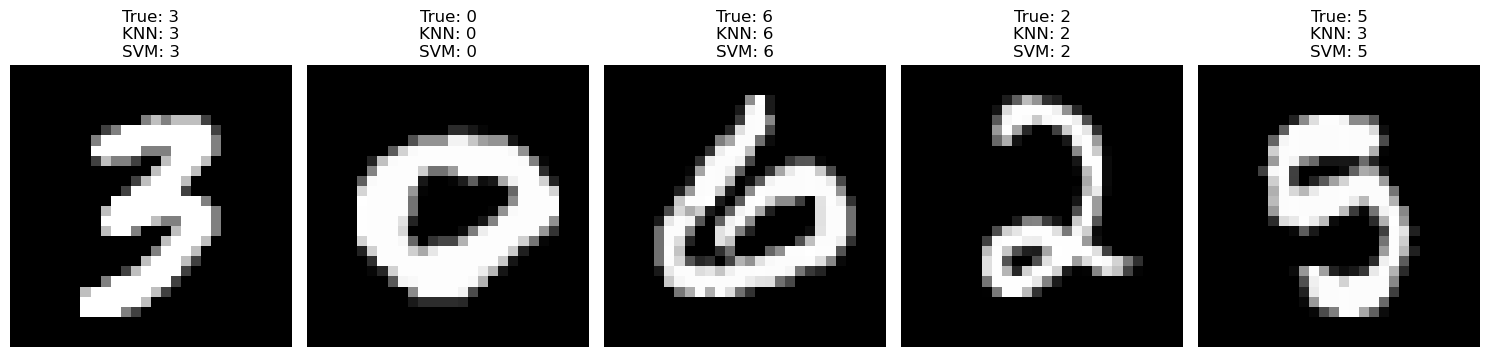

In [13]:
import matplotlib.pyplot as plt

num_images = 5
indices = np.random.choice(len(X_test), size=num_images, replace=False)

fig, axes = plt.subplots(1, num_images, figsize=(15, 5))
for i, idx in enumerate(indices):
    img = X_test[idx].reshape(28, 28) 
    true_label = y_test[idx]
    
    pred_knn = knn_model.predict([X_test[idx]])[0]
    pred_svm = svm_model.predict([X_test[idx]])[0]
    
    #Изображение
    axes[i].imshow(img, cmap='gray')
    axes[i].axis('off')
    
    # Легенда
    axes[i].set_title(f"True: {true_label}\nKNN: {pred_knn}\nSVM: {pred_svm}")

plt.tight_layout()
plt.show()
